In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
rf_results = pd.read_csv(
    "../data/processed/day9_random_forest_evaluation.csv"
)

xgb_results = pd.read_csv(
    "../data/processed/day10_xgboost_evaluation.csv"
)

print("Random Forest:")
display(rf_results.round(2))

print("XGBoost:")
display(xgb_results.round(2))

Random Forest:


,Model,MAE,RMSE,sMAPE
0,Random Forest,710.63,1036.48,10.51


XGBoost:


,Model,MAE,RMSE,sMAPE
0,XGBoost,697.11,999.25,10.32


In [3]:
comparison = pd.concat(
    [rf_results, xgb_results],
    ignore_index=True
)

comparison = comparison.sort_values(
    "MAE"
).reset_index(drop=True)

comparison.round(2)

,Model,MAE,RMSE,sMAPE
0,XGBoost,697.11,999.25,10.32
1,Random Forest,710.63,1036.48,10.51


In [4]:
best_model = comparison.iloc[0]

print("Best model on this validation window:", best_model["Model"])
print("MAE:", round(best_model["MAE"], 2))
print("RMSE:", round(best_model["RMSE"], 2))
print("sMAPE:", round(best_model["sMAPE"], 2), "%")

Best model on this validation window: XGBoost
MAE: 697.11
RMSE: 999.25
sMAPE: 10.32 %


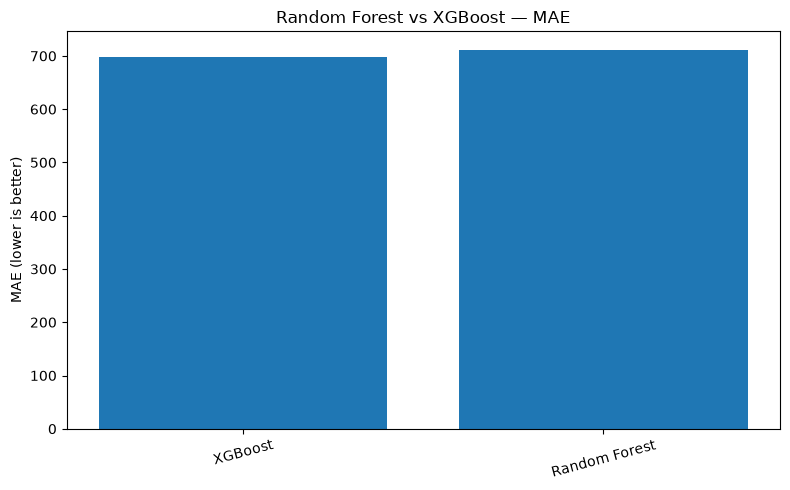

In [5]:
plt.figure(figsize=(8, 5))

plt.bar(comparison["Model"], comparison["MAE"])

plt.title("Random Forest vs XGBoost — MAE")
plt.ylabel("MAE (lower is better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [6]:
comparison.to_csv(
    "../data/processed/day11_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


# Day 11 — Model Comparison and Selection

## Objective
Compare Random Forest and XGBoost using consistent temporal validation.

## Evaluation Metrics
- MAE
- RMSE
- sMAPE

## Model Selection
The model with the lowest validation error is the initial candidate for selection. Other metrics and model complexity should also be considered.

## Validation Scope
Both models use the same chronological split strategy and feature table. Results apply to this validation window and should not be generalized to every store without further testing.

## Output
`data/processed/day11_model_comparison.csv`